# ARNIE Notebook



WARNING: If you have the datasets and want to use this notebook, you must connect to Google Colabs Tau4 (T4) High-RAM GPU. This unfortunately is not free.

Note: Generative AI was used in accordance with AI usage level 2x from brightspace, for research while developing ARNIE. See below for specific usage.

Specific GenAI model used: Claude-Sonnet-4.5

# Imports

In [ ]:
import tensorflow as tf

import numpy as np

from tensorflow.keras import datasets, layers, models, mixed_precision
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

from sklearn.model_selection import train_test_split

from keras import backend as K

import cv2

import matplotlib.pyplot as plt

from google.colab.patches import cv2_imshow

from tensorflow.keras import models, layers
from tensorflow.keras.models import Model

from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Concatenate, GlobalAveragePooling2D, Input, Flatten, BatchNormalization, Activation, Lambda

import os

from PIL import Image
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount = True)

Mounted at /content/drive


In [ ]:
# copy files to local session storage to prevent crashing
!cp -r "/content/drive/MyDrive/Sat Subsystems/ARNIE Training data/DATASETS" /content/datasets/

# Data

In [ ]:
train_files = [
  '/content/datasets/LoughErne1_20260408.npz',
  '/content/datasets/LoughNeagh1_20260408.npz',
  '/content/datasets/LoughNeagh2_20260408.npz',
  '/content/datasets/LoughErne2_20260410.npz',
  '/content/datasets/LoughNeagh3_20260410.npz',
]

In [ ]:
val_files = ['/content/datasets/LoughErne1_20260408.npz', '/content/datasets/LoughNeagh2_20260408.npz']

# Note
This is an area where GenAI was necessary to develop ARNIE. Naively, I produced 5 Gb of data (Which I still do believe is necessary for this task given the complexity, but is very difficult for actual use). However, trying to load this data into colab using methods I am accustomed to (i.e., mount drive, load data, perform train_test_split etc) caused the colab session to crash repeatedly. Hvaing found some information from the following sources:
- https://www.tensorflow.org/api_docs/python/tf/data/Dataset
- https://stackoverflow.com/questions/63140320/how-to-use-sequence-generator-on-tf-data-dataset-object-to-fit-partial-data-into

I did not understand how to use the tools mentioned in these sites to actually implement this.

GenAI suggested the use of tf.utils.Sequence and making a DataGenerator class, before wrapping it in a generator function.

GenAI assistance was used for the implementation of these methods. The alternatives were either attempt to debug this problem myself which likely would have meant ARNIE would not have been completed on time, or reduce the dataset size, meaning ARNIE would be unable to perform the task. The benefits (extremely fast loading and the session not crashing) allowed for ARNIE to be trained and perform well (at least on post training testing, at time of writing, inference performance remains to be tested).

In [ ]:
# MADE WITH THE ASSISTANCE OF GENAI - PLEASE SEE ABOVE
class DataGenerator(tf.keras.utils.Sequence):
  def __init__(self, file_paths, batch_size = 32, shuffle = True, validation = False, **kwargs):
    super().__init__(**kwargs)
    self.batch_size = batch_size
    self.shuffle = shuffle
    self.validation = validation

    images = []
    angles = []
    alts = []

    for path in file_paths:
      print(f"  Loading {path.split('/')[-1]}...")
      data = np.load(path)
      images.append(data['images'])
      angles.append(data['angles'])
      alts.append(data['altitudes'])

    self.images = np.concatenate(images, axis = 0)
    self.angles = np.concatenate(angles, axis = 0)
    self.alts = np.concatenate(alts, axis = 0)

    print(f"loaded {len(self.images)} images")

    self.indexes = np.arange(len(self.images))
    np.random.shuffle(self.indexes)

  def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

  @property
  def num_batches(self):
      return self.__len__()

  def get_num_batches(self):
        return self._length

  def __getitem__(self, index):
      batch_indexes = self.indexes[index*self.batch_size:(index+1)*self.batch_size]

      batch_ims = self.images[batch_indexes]
      batch_angles = self.angles[batch_indexes]
      batch_alts = self.alts[batch_indexes]

      X_img = batch_ims.astype(np.float32) / 255.0
      X_img = X_img[..., np.newaxis]

      # IF MAX MIN ALTS CHANGE MUST REMEMEBER T0 FIX THIS
      X_alt = (batch_alts.astype(np.float32) - 7.0) / (23.0 - 7.0)
      X_alt = X_alt.reshape(-1, 1)

      y = batch_angles.astype(np.float32)

      return {'image_input': X_img, 'alt_input': X_alt}, y

  def on_epoch_end(self):
      np.random.shuffle(self.indexes)

In [ ]:
# DONT USE A BATCH SIZE BIGGER THAN 32
train_gen = DataGenerator(train_files, batch_size=32, shuffle = True)

Loading data...
  Loading LoughErne1_20260408.npz...
  Loading LoughNeagh1_20260408.npz...
  Loading LoughNeagh2_20260408.npz...
  Loading LoughErne2_20260410.npz...
  Loading LoughNeagh3_20260410.npz...
loaded 33120 images


In [ ]:
val_gen = DataGenerator(val_files, batch_size=32, shuffle = False)

Loading data...
  Loading LoughErne1_20260408.npz...
  Loading LoughNeagh2_20260408.npz...
loaded 11520 images


In [ ]:
# MADE WITH THE ASSISTANCE OF GENAI - PLEASE SEE ABOVE
def generator_function():
    for i in range(len(train_gen)):
        yield train_gen[i]

train_dataset = tf.data.Dataset.from_generator(
    generator_function,
    output_signature=(
        {
            'image_input': tf.TensorSpec(shape=(None, 512, 512, 1), dtype=tf.float32),
            'alt_input': tf.TensorSpec(shape=(None, 1), dtype=tf.float32)
        },
        tf.TensorSpec(shape=(None, 2), dtype=tf.float32)
    )
).repeat().prefetch(tf.data.AUTOTUNE)

def val_generator_function():
    for i in range(len(val_gen)):
        yield val_gen[i]

val_dataset = tf.data.Dataset.from_generator(
    val_generator_function,
    output_signature=(
        {
            'image_input': tf.TensorSpec(shape=(None, 512, 512, 1), dtype=tf.float32),
            'alt_input': tf.TensorSpec(shape=(None, 1), dtype=tf.float32)
        },
        tf.TensorSpec(shape=(None, 2), dtype=tf.float32)
    )
).repeat().prefetch(tf.data.AUTOTUNE)

# Model

# Justification of the Cosine loss function:
- In ML, the loss function quantifies the difference between the output of the model and the ground truth. For ARNIE's task, a simple mean square error ('mse') or mean absolute error ('mae') would be poor choices, given the angle wrapping at 0° - 359°. While numerically very different, they are essentially the same angle. Cosine loss, or cosine similarity, was chosen as this handles the angular discontinuity, and measures angular difference rather than numeric difference.

For more on the cosine loss function
 - https://arxiv.org/pdf/1901.09054
 - https://stats.stackexchange.com/questions/668447/what-is-a-suitable-loss-function-for-predicting-cos%CF%86-and-sin%CF%86-of-a-circular
 - https://www.geeksforgeeks.org/machine-learning/python-tensorflow-math-l2_normalize/
 - https://www.geeksforgeeks.org/machine-learning/python-tensorflow-math-reduce_sum/
 - https://www.geeksforgeeks.org/machine-learning/python-tensorflow-math-reduce_mean/

In [ ]:
def cosine_loss(y_true, y_pred):
    y_pred_norm = tf.nn.l2_normalize(y_pred + 1e-8, axis=-1) # normalise vectors to between [0, 1], 1e-8 added to prevent dividing by zero
    cos_similarity = tf.reduce_sum(y_true * y_pred_norm, axis=-1) # dot product the true and pred vectors (assumes t_true normalised because of cos sin encodeing)

    # convert similarity to loss (0 is perfect match (1 - 1), 2 is opposoite (1 - (-1)))
    loss = 1.0 - cos_similarity

    return tf.reduce_mean(loss) # get mean of loss across the bacth being used

In [ ]:
#                         w,   h,  c
img_input = Input(shape=(512, 512, 1), name='image_input')

# Level 1
x = Conv2D(32, (7, 7), strides=2, padding='same')(img_input)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Conv2D(32, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

# Level 2
x = Conv2D(64, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Conv2D(64, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

#Level 3
x = Conv2D(128, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Conv2D(128, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

# Level 4
x = Conv2D(256, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

x = GlobalAveragePooling2D()(x)

alt_input = Input(shape = (1,), name = 'alt_input')
alt_norm = Dense(16, activation = 'relu')(alt_input)

x = Concatenate()([x, alt_norm])
x = Dense(512, activation='relu')(x)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.2)(x)
output = Dense(2, dtype = 'float32', name = 'angle_output')(x)

ARNIE_Simple = tf.keras.Model(inputs=[img_input, alt_input], outputs= output)

ARNIE_Simple.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001, clipnorm=1.0),
    loss=cosine_loss,
    metrics=['mae'])

# Justification of layers chosen:

- img_input: The shape of the image being given to the model (width, length, channel). Given that ARNIE expects greysacle images, the shape is (512, 512, 1)

- Conv2D: The most important layer of the CNN. This allows for spatial features to be extracted by the model by applying a kernel to detect patterns

- BatchNorm: Normalises the models inputs, which helps to stabilise training. This layer is particularly important fot making ARNIE robust to lighting or contrast variations.

- ReLU activation: Introduces non-linearity in the model. Essentially, allows the model to learn more complex patterns. In other words, it allows the model to understand features simulataneously (i.e., a shoreline and island present both indicate attitude, and both are important)

- MaxPooling2D: Reduces spatial dimensions by taking min values in local regions. This makes ARNIE robust to slight translational variations, which is very important as ARNIE likely won't see the exact images it was trained on.

- GlobalAvgPooling2D: Converts 2D feature maps into single values. It acts as a summary of detectable features present, and adds further robustness to small variance in position.

- Dense: Another of the most important layers of the CNN. This combines the extracted features into the final prediction. It combines info from all detected features, and produces the attitude.

- Droput: Randomly deactivates neurons in the CNN. This is crucial to prevent overfitting. While ARNIE was purposefully overfitted to the target operating zone, this layer was necessary to reduce overfitting to specifc characteristcis of the images ARNIE was trained on.

- Note: Referring to ReLU activation: This the 'activation layer', which is extremely important, and basically separates a deep network from being a simple linear regression model. More info:

https://www.geeksforgeeks.org/machine-learning/activation-functions-neural-networks/

References:
- https://www.geeksforgeeks.org/machine-learning/python-tensorflow-tf-keras-layers-conv2d-function/
- https://dev.to/sarvesh42/understanding-conv2d-layer-with-tensorflow-implementation-32h8
- https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization
- https://www.geeksforgeeks.org/deep-learning/applying-batch-normalization-in-keras-using-batchnormalization-class/
- https://www.geeksforgeeks.org/deep-learning/relu-activation-function-in-deep-learning/
- https://medium.com/ai-enthusiast/understanding-relu-the-activation-function-driving-deep-learning-success-1cbe58eb555a
- https://medium.com/@sourenh94/understanding-relu-activation-function-in-convolutional-neural-networks-691614493bcb
- https://www.geeksforgeeks.org/javascript/tensorflow-js-tf-layers-maxpooling2d-function/
- https://www.geeksforgeeks.org/javascript/tensorflow-js-tf-layers-globalaveragepooling2d-function/
- https://stackabuse.com/dont-use-flatten-global-pooling-for-cnns-with-tensorflow-and-keras/
- https://medium.com/analytics-vidhya/opening-the-black-box-of-machine-learning-tensorflow-dense-layers-8164441ed38f
- https://www.geeksforgeeks.org/deep-learning/dense-layer-tf-keras-layers-dense-in-tensorflow/
- https://stackoverflow.com/questions/60783216/what-exactly-does-tf-keras-layers-dense-do
- https://wandb.ai/ayush-thakur/keras-dense/reports/Keras-Dense-Layer-How-to-Use-It-Correctly--Vmlldzo0MjAzNDY1
- https://medium.com/@vishnuam/dropout-in-convolutional-neural-networks-cnn-422a4a17da41
- https://medium.com/@dipti.rohan.pawar/improving-performance-of-convolutional-neural-network-2ecfe0207de7

- Machine Learning with Python (OL) lecture notes - COMP47750 - Dr. Padraig Cunningham

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=6,
    min_lr=0.00001,
    verbose=1
)

# Justification of callbacks

- early_stop: While ARNIE was overfitted to the target region, early_stop was used to avoid overfitting, and prevent wasting Golab compute units when training was no longer improving. 'return_best_weights' was very useful, as the best model is not always the one produced at the final epoch of training. Early stopping serves to prevent severe overfitting by the model, where the model learns the noise and variation of the data, rather than the pattern. This is important fro ARNIE as realistic conditions will likely differ from training data.

- reduce_lr: This metric was crucial in ARNIE's training. The learning rate controls the size of the steps taken by the model as it operforms gradient descent for updating its weights. Too big, and the model will overshoot the desired minima points. Too small, and the model will get stuck in local minima and never converge. This callback was added late into ARNIE's development, and significantly imoroved training speed and the models overall quality. TensorFlows standard optimiser, 'Adam', was used at the start of training, with a very small hardcoded learning rate. This was then updated by this callback once the models training plataued.


References:
- https://cyborgcodes.medium.com/what-is-early-stopping-in-deep-learning-eeb1e710a3cf
- https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ReduceLROnPlateau
- https://medium.com/@zhonghong9998/adaptive-learning-rate-scheduling-optimizing-training-in-deep-networks-14d4f95a45d6
- https://www.geeksforgeeks.org/python/adam-optimizer-in-tensorflow/

In [ ]:
# lower mixed precision for faster model training
# this single step made training ARNIE possible at all, otherwise training time
# would have been days
mixed_precision.set_global_policy('mixed_float16')

In [ ]:
history = ARNIE_Simple.fit(
    train_dataset,
    validation_data=val_dataset,
    steps_per_epoch = len(train_gen),
    validation_steps = len(val_gen),
    epochs= 5,
    callbacks = [reduce_lr, early_stop],
    verbose=1
)

Epoch 1/5
1035/1035 ━━━━━━━━━━━━━━━━━━━━ 235s 227ms/step - loss: 0.0608 - mae: 0.8662 - val_loss: 0.0485 - val_mae: 1.1446 - learning_rate: 2.5000e-05
Epoch 2/5
1035/1035 ━━━━━━━━━━━━━━━━━━━━ 234s 226ms/step - loss: 0.0594 - mae: 0.8719 - val_loss: 0.0459 - val_mae: 1.1826 - learning_rate: 2.5000e-05
Epoch 3/5
1035/1035 ━━━━━━━━━━━━━━━━━━━━ 234s 226ms/step - loss: 0.0597 - mae: 0.8472 - val_loss: 0.0440 - val_mae: 1.1245 - learning_rate: 2.5000e-05
Epoch 4/5
1035/1035 ━━━━━━━━━━━━━━━━━━━━ 233s 226ms/step - loss: 0.0579 - mae: 0.8324 - val_loss: 0.0962 - val_mae: 1.2618 - learning_rate: 2.5000e-05
Epoch 5/5
1035/1035 ━━━━━━━━━━━━━━━━━━━━ 234s 226ms/step - loss: 0.0561 - mae: 0.8227 - val_loss: 0.0248 - val_mae: 1.0896 - learning_rate: 2.5000e-05


# Testing

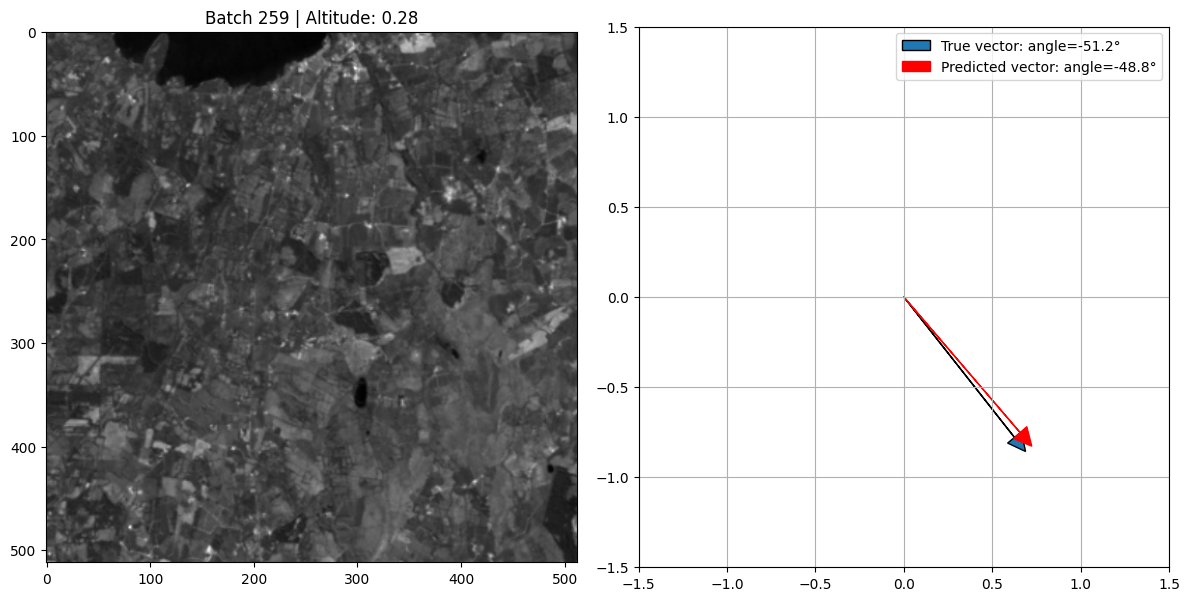

In [ ]:
# get a random batch
i = np.random.randint(0, 1000)
batch = train_gen[i]
X, y_true = batch

y_pred_raw = ARNIE_Simple.predict({'image_input': X['image_input'][:1],
                                    'alt_input': X['alt_input'][:1]}, verbose=0)
y_pred = y_pred_raw / np.linalg.norm(y_pred_raw)
pred_angle = np.arctan2(y_pred[0, 1], y_pred[0, 0]) * 180 / np.pi

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(X['image_input'][0, :, :, 0], cmap='gray')
plt.title(f"Batch {i} | Altitude: {X['alt_input'][0, 0]:.2f}")

plt.subplot(1, 2, 2)
true_angle = np.arctan2(y_true[0, 1], y_true[0, 0]) * 180 / np.pi
plt.arrow(0, 0, y_true[0, 0], y_true[0, 1], head_width=0.1, head_length=0.1, label = f"True vector: angle={true_angle:.1f}°")

plt.arrow(0, 0, y_pred[0, 0], y_pred[0, 1], head_width=0.1, head_length=0.1, color='red', label =f"Predicted vector: angle={pred_angle:.1f}°")
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# TF LITE CONVERSION

In [ ]:
# return model to float32 for tflite

mixed_precision.set_global_policy('float32')

ARNIE_Simple.save('arnie_model.keras')

ARNIE_fp32 = tf.keras.models.load_model(
    'arnie_model.keras',
    custom_objects={'cosine_loss': cosine_loss}
)

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(ARNIE_fp32)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]

tflite_model = converter.convert()

with open('arnie_pure_tflite.tflite', 'wb') as f:
    f.write(tflite_model)

print(f"Size: {len(tflite_model) / 1024 / 1024:.2f} MB")
print('Come with me if you want to live')

# Justification for mixed precision usage:

- float16:
By reducing the precision to float16, the accuracy to which numbers are considered is halved (i.e., from 32 digits of accruacy to 16). The benefits of this are apparent, the model trains and converges much faster. While there is a risk of accuracy decrease. ARNIE would not have been trained in time without this implemented.

- float32:
If the above with float16 grealy increasing training speed seems too good to be true, it is. After spending 3.5 hours training ARNIE v1, the model produced was excellent, and performed very well. However, this made tflite conversion fail, and produce a massive error message. In trying to resolve the issue, thinking it was a tensorflow/tflite version conflict (tensorflow lite 2.19 released on the 4th March 2026), I installed an older version. In doing so, the session crashed and I lost that model. The solution I had missed - just recast to float32 prior to conversion.

References:
-  https://stackoverflow.com/questions/46613748/float16-vs-float32-for-convolutional-neural-networks
- https://massedcompute.com/faq-answers/?question=Can%20you%20explain%20the%20impact%20of%20float16%20and%20float32%20on%20deep%20learning%20model%20accuracy?
- https://www.tensorflow.org/guide/mixed_precision